# Particles in a laboratory jaw: what following every particle adds to a population balance, and what the laboratory tests measured

**Question:** What does following every particle add to a population balance of a crusher, and what did the laboratory jaw tests of Barrios et al. (2020) measure that a particle simulation has to be held against?

- **Level:** 1, fundamentals
- **Prerequisites:** none inside this topic; topics 03 and 04 give the population balance and the capacity model that this topic sets beside the particle simulation
- **Reading time:** about 50 minutes (the live batch takes about one minute)

## Objectives

By the end of this notebook you can:

- say what a population balance of a crusher assumes about the chamber and what a discrete element simulation adds by following each particle;
- state the machine, the three narrow feeds and the three kinds of measurement of the laboratory jaw tests, with the page of the paper that each number was read from;
- write the two laws that make the method, Newton's second law with the Hertz contact for every sphere and the breakage condition of a sphere against its fracture energy, with every symbol defined;
- run the package's laboratory jaw case on a batch of 0.5 kg, read what each stroke did to the mass, the plate power and the overlap, and say why a batch this small cannot be held against the measurement.

## Setup

The particle engine is the published package `crushdem` (version 0.6.0), installed with its compiled CPU kernels; numba and llvmlite are pinned at the releases that the product's bake uses.

```bash
pip install "crushdem[jit]==0.6.0" numba==0.68.1 llvmlite==0.50.0 numpy==2.4.6 matplotlib==3.11.2
```

The cell prints the versions, finds the repository root and imports the package's laboratory jaw case (`crushdem.cases.barrios2020`), its comparison protocol, its contact and breakage functions, and the three operating points of the product's bake (`pipeline.dem.points`).

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import contextlib
import importlib.metadata as md
import io
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('crushdem', 'numba', 'llvmlite', 'numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public functions only: the notebook defines no method of its own
from crushdem import comparison
from crushdem.breakage import breakage_probability, fracture_energy_from_probability, median_fracture_energy
from crushdem.cases import barrios2020 as case
from crushdem.core.materials import effective_modulus, energy_share, tsuji_alpha
from crushdem.core.state import rayleigh_time_step
from pipeline.dem import points as P
plt.rcParams.update({"figure.figsize": (8.6, 3.8), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

crushdem 0.6.0
numba 0.68.1
llvmlite 0.50.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The measurements of the laboratory jaw crusher of Barrios, Jimenez-Herrera, Fuentes-Torres and Tavares (2020), Minerals 10(8), 717, https://doi.org/10.3390/min10080717, open access under CC BY 4.0 (`conventions/third-party-datasets.md`). The paper prints the machine in its Table 2 (page 3) and plots the results as figures; the package holds the figures digitised twice, with their difference as the digitisation noise, as package data (`crushdem/cases/data/barrios2020_digitised.json`), and `crushdem.cases.barrios2020.measured` returns them by feed class. Only the cost cell of the method reads a file of this repository, the committed document of the bake.

The tests crushed batches of about 6 kg at one setting only: a stroke frequency of 6.0 Hz and a closed side setting of 7.5 mm. Three narrow feeds were used, 63/52, 31.5/26.5 and 16/13.2 mm, named by the upper and lower sieve. Throughput was measured with an integrating load cell, net power from an amperage multimeter and the product with a stack of laboratory sieves (page 3). The first cell prints the machine of Table 2.

In [2]:
# The machine of Table 2 of the paper, as the package holds it
table_2 = case.PAPER["machine_table_2_p3"]
opening = table_2["feed_opening_mm"]
print(f"feed opening {opening[0]:g} x {opening[1]:g} mm,",
      f"closed side {table_2['discharge_opening_closed_mm'][1]:g} mm,",
      f"throw {table_2['swing_jaw_throw_mm']:g} mm,",
      f"stroke frequency {table_2['swing_jaw_stroke_frequency_hz']:g} Hz")
print(f"nominal throughput {table_2['nominal_throughput_kg_h']:g} kg/h,",
      f"motor {table_2['motor_power_kw']:g} kW,",
      f"main shaft {table_2['main_shaft_rpm']:g} rpm,",
      f"open side (closed side plus throw) {case.OPEN_SIDE_MM:g} mm")

feed opening 140 x 90 mm, closed side 7.5 mm, throw 10 mm, stroke frequency 6 Hz
nominal throughput 300 kg/h, motor 2.2 kW, main shaft 400 rpm, open side (closed side plus throw) 17.5 mm


The second reading cell takes the three feed classes from the product's operating points and, for each, the measured throughput, net power and product curve that `measured` returns, with the page of the paper that holds the power.

In [3]:
# One row per feed: the measured throughput, net power and product curve that the package holds
feeds = [p.feed_class for p in P.POINTS]
measured = {fc: case.measured(fc) for fc in feeds}
mean_size_mm = {fc: 0.5 * (p.lower_mm + p.upper_mm) for fc, p in zip(feeds, P.POINTS)}
print("feed [mm]  mean size [mm]  throughput [kg/h]  net power [kW]  page")
for fc in feeds:
    m = measured[fc]
    print(f"{fc:>10s} {mean_size_mm[fc]:14.1f} {m.throughput_kg_h:18.1f} {m.net_power_kw:14.4f} {m.net_power_page:10d}")

feed [mm]  mean size [mm]  throughput [kg/h]  net power [kW]  page
     63/52           57.5              798.7         0.3400         10
 31.5/26.5           29.0              937.2         0.1656         12
   16/13.2           14.6             1220.4         0.1346         12


What is measured is one number of throughput and one of net power per feed (the bars are the difference between the two digitisation passes, which is below the width of a marker), and a product curve per feed. The net power of the coarsest feed is the 0.34 kW the paper states in its text; the other two powers are read from Fig. 14b. The next cell turns the two numbers of each feed into a specific energy, the energy the machine draws per kilogram it passes, and sets the throughput against the nominal 300 kg/h of Table 2.

In [4]:
# The specific energy the measurements imply: net power over throughput, in J/kg and kWh/t
nominal = case.PAPER["machine_table_2_p3"]["nominal_throughput_kg_h"]
for fc in feeds:
    m = measured[fc]
    j_per_kg = m.net_power_kw * 1000.0 * 3600.0 / m.throughput_kg_h
    ratio = m.throughput_kg_h / nominal
    print(f"{fc:>10s}: {j_per_kg:7.0f} J/kg = {j_per_kg / 3600.0:6.3f} kWh/t;",
          f"throughput over the nominal {ratio:4.2f}")

     63/52:    1533 J/kg =  0.426 kWh/t; throughput over the nominal 2.66
 31.5/26.5:     636 J/kg =  0.177 kWh/t; throughput over the nominal 3.12
   16/13.2:     397 J/kg =  0.110 kWh/t; throughput over the nominal 4.07


Figure 1 plots the two series against the mean size of each feed (57.5, 29.0 and 14.6 mm), with the nominal throughput of the machine as a dashed line.

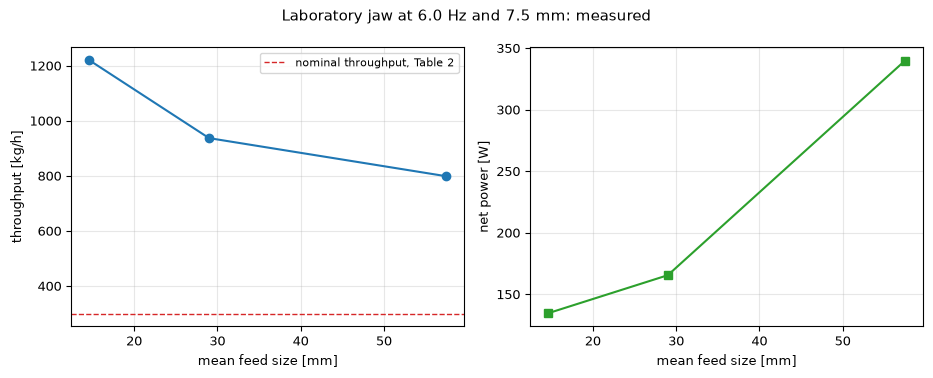

In [5]:
# Figure 1: the measured throughput and net power of the three feeds against their mean size
sizes = [mean_size_mm[fc] for fc in feeds]
q = [measured[fc].throughput_kg_h for fc in feeds]
q_noise = [measured[fc].throughput_noise_kg_h for fc in feeds]
power_w = [measured[fc].net_power_kw * 1000 for fc in feeds]
power_noise = [measured[fc].net_power_noise_kw * 1000 for fc in feeds]
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8))
axes[0].errorbar(sizes, q, yerr=q_noise, fmt="o-", capsize=3)
axes[0].axhline(nominal, color="tab:red", ls="--", lw=1, label="nominal throughput, Table 2")
axes[0].set_xlabel("mean feed size [mm]")
axes[0].set_ylabel("throughput [kg/h]")
axes[0].legend(fontsize=8)
axes[1].errorbar(sizes, power_w, yerr=power_noise, fmt="s-", color="tab:green", capsize=3)
axes[1].set_xlabel("mean feed size [mm]")
axes[1].set_ylabel("net power [W]")
fig.suptitle("Laboratory jaw at 6.0 Hz and 7.5 mm: measured")
fig.tight_layout()
plt.show()

Reading figure 1: the finer the feed, the more the machine passes, 798.7 kg/h for the 63/52 mm feed against 1220.4 kg/h for the 16/13.2 mm one, and the less power it draws, 0.34 kW against 0.1346 kW. All three throughputs lie 2.66 to 4.07 times above the 300 kg/h nominal of the machine's table. The specific energy printed above therefore falls by a factor of nearly four from the coarsest to the finest feed, from 1533 to 397 J/kg: a coarse particle takes more crushing strokes, and the energy follows. The figure does not show how the power varies inside a test (the paper plots it for 25 s, Fig. 12a), nor any measurement at another frequency or setting, because the paper made none; the sweeps of its Figs. 15 to 17 are simulations.

Figure 2 draws the three product curves of Fig. 7a, and the cell reads from each the sizes at 50 and 80 percent passing by linear interpolation between sieves; P80 is the size that a population balance reports and that a reduction ratio, the feed F80 over the product P80, is built on.

     63/52: P50  4.46 mm, P80  7.12 mm, digitisation noise, at most 0.42 points
 31.5/26.5: P50  4.83 mm, P80  7.62 mm, digitisation noise, at most 0.16 points
   16/13.2: P50  5.15 mm, P80  7.83 mm, digitisation noise, at most 0.30 points


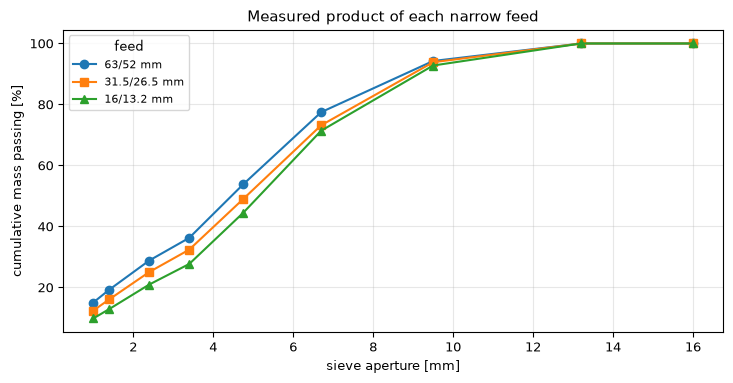

In [6]:
# Figure 2: the three measured product curves; P50 and P80 are read from each by linear interpolation
fig, ax = plt.subplots(figsize=(7.4, 3.9))
marks = {"63/52": "o", "31.5/26.5": "s", "16/13.2": "^"}
for fc in feeds:
    prod = measured[fc].product
    ax.plot(prod["sizes_mm"], prod["passing_pct"], marks[fc] + "-", label=fc + " mm")
    p50 = float(np.interp(50.0, prod["passing_pct"], prod["sizes_mm"]))
    p80 = float(np.interp(80.0, prod["passing_pct"], prod["sizes_mm"]))
    print(f"{fc:>10s}: P50 {p50:5.2f} mm, P80 {p80:5.2f} mm,",
          f"digitisation noise, at most {prod['noise_pct_max']:.2f} points")
ax.set_xlabel("sieve aperture [mm]")
ax.set_ylabel("cumulative mass passing [%]")
ax.set_title("Measured product of each narrow feed")
ax.legend(title="feed", fontsize=8)
fig.tight_layout()
plt.show()

Reading figure 2: every product is entirely below 16 mm, and the three curves are close, with P80 between 7.1 and 7.8 mm for feeds whose upper sizes are 63, 31.5 and 16 mm; a feed four times coarser gives a product about 9 percent finer (P80 7.12 against 7.83 mm). The product therefore carries little memory of the feed size: the coarsest feed, which is broken more times, ends slightly finer, and what sets the product is the closed side and the breakage, which is what the two classification parameters of a population balance encode. The figure does not show the 100 percent point of the finest sieves exactly: the paper's 13.2 and 16 mm markers sit on the 100 percent line under other markers, and the package takes them as 100.

## Method

### Why follow every particle

A population balance of a crusher, such as the Whiten model of topic 03, treats the chamber as one place with two functions: a classification curve that says which sizes are caught and a breakage function that says what a caught particle becomes (Whiten, 1972). Its constants are fitted per machine and ore, and the geometry, the stroke and the contacts enter only through them. That makes it cheap, a linear solve, and blind to what happens between the plates. A discrete element simulation gives the chamber back its mechanics: every particle is a sphere with a position, a velocity and a spin, the plates move by the machine's own law, throughput is the mass that falls through the gap, power is the force of the moving plate on the bed times its velocity, and the product is whatever the breakage events produce. Cleary and Sinnott (2015) built compression crushers this way by replacing a sphere with its fragments when it breaks, and Barrios et al. (2020) did it for the jaw of this notebook, breaking a particle when its contact force passes a threshold calibrated on single-particle tests and replacing it with a fixed set of daughters; the package used here replaces by the energy-based breakage model of Tavares (2022) instead.

The price is the number of things followed. The smallest sphere that the run keeps, of 4 mm, sets a time step of 3.559 microseconds, fixed by the speed at which a stress wave crosses a sphere, so one stroke of the jaw at 6.0 Hz needs tens of thousands of steps, each of which visits every contact. Quist (2012) reports 172 and 404 CPU hours on 8 cores for a quarter of an industrial cone crusher with 50 364 and 92 508 bonded particles, and the package's own full batch of 6 kg of the coarsest feed takes about 80 strokes at 10 to 40 s of wall time each on the CPU path (the package's README, https://pypi.org/project/crushdem/). A population balance answers in milliseconds; this notebook has to say what the extra cost buys.

### The two laws of the method

Every sphere $i$ obeys Newton's second law for its translation and its spin, with the forces of its contacts, of gravity and of the walls:

$$m_i \frac{d\mathbf v_i}{dt} = m_i \mathbf g + \sum_{j} \left(F_{n,ij}\,\mathbf n_{ij} + \mathbf F_{t,ij}\right) + \sum_{w} \mathbf F_{iw}, \qquad I_i \frac{d\boldsymbol\omega_i}{dt} = \sum_j R_i\, \mathbf n_{ij} \times \mathbf F_{t,ij},$$

where $m_i$, $I_i$ and $R_i$ are the mass, moment of inertia and radius of the sphere, $\mathbf v_i$ and $\boldsymbol\omega_i$ its velocity and spin, $\mathbf g$ gravity, $\mathbf n_{ij}$ the unit normal from $i$ to $j$, $F_{n,ij}$ and $\mathbf F_{t,ij}$ the normal and tangential contact forces and $\mathbf F_{iw}$ the force of a wall. The display leaves out the rolling-resistance torque that the package adds with the rolling friction of Tables 3 and 4 (0.25 between ore spheres, 0.10 between ore and steel). The normal force is the Hertz law with the damping of Tsuji, Tanaka and Ishida (1992), after the contact model of Cundall and Strack (1979):

$$F_n = \tfrac{4}{3} E^{*} \sqrt{R^{*}}\,\delta^{3/2} + \eta_n v_n, \qquad \eta_n = \alpha(e)\sqrt{m^{*} k_{nd}}, \quad k_{nd} = \tfrac{4}{3} E^{*} \sqrt{R^{*}\delta},$$

with $\delta$ the overlap of the two spheres, $E^{*}$ and $R^{*}$ their effective modulus and radius, $v_n$ the approach speed of the contacts, $m^{*}$ the reduced mass, $e$ the coefficient of restitution and $\alpha(e)$ the damping constant fitted by Tsuji et al. The overlap is an artefact of the method, because real rock does not interpenetrate; it stands for the elastic deformation, and the method stays valid only while it is a small fraction of the radius. The package refuses a run whose largest overlap passes a stated fraction of the smaller radius (0.3 unless told otherwise), and topic 09's later notebooks show that this is the limit the jaw hits.

The second law is the breakage condition. A sphere takes in the energy that its contacts do work with while they load it. Tavares (2022) models the specific fracture energy $E$ of a particle of size $d$ as a lognormal distribution:

$$P(E) = \tfrac{1}{2}\left[1 + \operatorname{erf}\!\left(\frac{\ln E - \ln E_{50}(d)}{\sqrt{2\sigma^{2}}}\right)\right], \qquad E_{50}(d) = E_\infty\left[1 + \left(\frac{d_0}{d}\right)^{\phi}\right],$$

where $E_{50}$ is the median fracture energy [J/kg], $\sigma^{2}$ the variance of its logarithm and $E_\infty$, $d_0$ and $\phi$ the parameters of the size effect, small particles being stronger per unit of mass. Each sphere draws one uniform number $u$ when it appears; its fracture energy is the energy at which $P(E) = u$, and it breaks in an event of specific energy $E_k$ exactly when $e\,E_k \ge E_{\text{frac}}\,(1 - D)$, with $e$ the share of the contact work that goes into the sphere and $D$ the damage that earlier, weaker events left in it. The sphere is then replaced by smaller spheres that carry the same mass, whose sizes follow from the event energy (the subject of notebook 02).

The cell evaluates the contact of the jaw with the package's functions. The ore and the steel are the two materials of the paper's Tables 3 and 4 as `crushdem.cases.barrios2020` holds them; the cell prints the effective modulus of the ore against steel, the share of the contact work that goes into the ore (Tavares's equation 9), the damping constant at the ore-steel restitution of 0.37, the stable time step at a tenth of the Rayleigh time of a 16 mm and a 4 mm sphere, and the Hertz force of a 14.6 mm sphere pressed 0.05 mm into a steel plate.

In [7]:
# The contact of the jaw through the package: effective modulus, energy share, damping constant, time step
ore_mat, steel_mat = case.ORE_MATERIAL, case.STEEL_MATERIAL
e_star = effective_modulus(ore_mat, steel_mat)
share = energy_share(ore_mat, steel_mat)
print(f"E* ore against steel {e_star:.4g} Pa,",
      f"energy share of the ore e = {share:.4f}")
print(f"Tsuji constant at a restitution of 0.37: alpha = {tsuji_alpha(0.37):.4f}")
for d_mm in (16.0, 4.0):
    dt_r = rayleigh_time_step(0.5 * d_mm * 1e-3, ore_mat)
    print(f"Rayleigh time of a {d_mm:g} mm sphere: {dt_r:.3e} s ({dt_r * 1e6:.2f} us),",
          f"a tenth of it {0.1 * dt_r:.3e} s = {0.1 * dt_r * 1e6:.3f} microseconds")
# Hertz force of a 14.6 mm ore sphere pressed 0.05 mm into steel (R* is the sphere radius)
radius, overlap = 0.5 * mean_size_mm["16/13.2"] * 1e-3, 5.0e-5
force = 4.0 / 3.0 * e_star * np.sqrt(radius) * overlap ** 1.5
print(f"Hertz force at an overlap of {overlap * 1e3:.2f} mm",
      f"({overlap / radius * 100:.2f} percent of the radius): {force:.1f} N")

E* ore against steel 2.632e+08 Pa, energy share of the ore e = 0.9868
Tsuji constant at a restitution of 0.37: alpha = 0.6757
Rayleigh time of a 16 mm sphere: 1.424e-04 s (142.36 us), a tenth of it 1.424e-05 s = 14.236 microseconds
Rayleigh time of a 4 mm sphere: 3.559e-05 s (35.59 us), a tenth of it 3.559e-06 s = 3.559 microseconds
Hertz force at an overlap of 0.05 mm (0.68 percent of the radius): 10.6 N


The effective modulus is 2.632e+08 Pa and the ore takes 0.9868 of the contact work, because the steel is so much stiffer that nearly all of it deforms the rock. A 14.6 mm sphere pressed 0.05 mm, 0.68 percent of its radius, carries a force of 10.6 N; the force grows with the overlap to the power 3/2, so a ten times larger overlap carries about 32 times more. The Rayleigh time of the 4 mm sphere that the product keeps as its smallest, 35.59 microseconds, is what sets the step of 3.559 microseconds used throughout, a tenth of it.

The next cell takes the ore of the paper in the way the package derives it from the 30 single-particle tests per size class of the paper's Fig. 6b (notebook 02 follows the derivation) and evaluates the breakage condition on a sphere of the 16/13.2 mm feed: its median fracture energy, the probability of breaking in events from a quarter to four times that energy, and the fracture energy of spheres whose draw is 0.1, 0.5 and 0.9.

In [8]:
# The paper's ore as the package derives it from the single-particle tests, and the breakage law on one sphere
ore, derivation = case.paper_ore("A", seed=1)
d_sphere = mean_size_mm["16/13.2"] * 1e-3
e50 = median_fracture_energy(d_sphere, ore)
print(f"median fracture energy at {d_sphere * 1e3:.1f} mm: E50 = {e50:.1f} J/kg,",
      f"variance of the logarithm {ore.variance:.2f}")
print("E50 of the three single-particle classes [J/kg]:",
      {k: round(v, 1) for k, v in derivation["e50_j_kg"].items()})
print("event energy [J/kg]   probability of breaking")
for factor in (0.25, 0.5, 1.0, 2.0, 4.0):
    print(f"{factor * e50:14.1f} {breakage_probability(factor * e50, d_sphere, ore):20.3f}")
# One uniform draw per sphere fixes its fracture energy, the inverse of that probability
for u in (0.1, 0.5, 0.9):
    energy_u = fracture_energy_from_probability(u, d_sphere, ore)
    print(f"u = {u}: fracture energy {energy_u:.1f} J/kg")
spread = fracture_energy_from_probability(0.9, d_sphere, ore) / fracture_energy_from_probability(0.1, d_sphere, ore)
print(f"ratio of the fracture energies at u = 0.9 and u = 0.1: {spread:.2f}")

median fracture energy at 14.6 mm: E50 = 168.6 J/kg, variance of the logarithm 1.20
E50 of the three single-particle classes [J/kg]: {'63/53': 26.6, '31.5/26.5': 58.2, '16.0/13.2': 451.1}
event energy [J/kg]   probability of breaking
          42.2                0.103
          84.3                0.263
         168.6                0.500
         337.2                0.737
         674.4                0.897
u = 0.1: fracture energy 41.4 J/kg
u = 0.5: fracture energy 168.6 J/kg
u = 0.9: fracture energy 686.4 J/kg
ratio of the fracture energies at u = 0.9 and u = 0.1: 16.57


The median fracture energy of a sphere of 14.6 mm is 168.6 J/kg, and the variance of the logarithm of 1.20 is wide: an event at a quarter of the median breaks one sphere in ten, one at four times the median leaves one in ten unbroken, and the spheres at the extremes of the draw differ by a factor of 16.57 in fracture energy (41.4 against 686.4 J/kg). Two spheres of one size, in the same contact, therefore break at different moments, which is how a deterministic contact law and a random strength give the scatter that a real batch shows. The median is large next to the 26.6 and 58.2 J/kg of the 63/53 and 31.5/26.5 mm classes, because the size effect makes small particles strong per unit of mass; that is the extrapolation the finest feed rests on and notebook 02 returns to it.

### A first live batch

The cell runs the package's own stroke loop on the laboratory jaw: `run_attempt` builds the jaw and its contact table, feeds 0.5 kg of the 16/13.2 mm feed, runs one stroke at a time and records after each the mass held in the chamber, the mass passed, the mean power of the swing plate and the largest overlap seen. It stops when the batch is out, when nothing passes for 40 strokes, or at the stroke limit, six here. The arguments are the ore, the batch mass, the stroke frequency, the seed, the number of slots for particles, the overlap limit (0.5 here, the top of the ladder the product's bake uses), the backend and the run limits. The package prints its own progress line with a wall clock, and the cell silences it so that the output stays the same on every run.

In [9]:
# A live batch: 0.5 kg of the 16/13.2 mm feed, six strokes at most, the package's run control; its progress line
# is silenced
with contextlib.redirect_stdout(io.StringIO()):
    attempt = case.run_attempt(ore, 0.5, 6.0, 1, 800, 0.5, "numba", 6, 600.0, 40, feed_class="16/13.2")
steps_per_stroke = attempt["steps"] // attempt["strokes"]
print("status:", attempt["status"], "|", attempt["strokes"], "strokes,", attempt["steps"],
      "steps of", f"{attempt['dt_s']:.3e}", "s,", steps_per_stroke, "steps per stroke")
print("stroke  spheres held  held [kg]  passed [kg]  plate power [W]  largest overlap")
for row in attempt["series"]:
    print(f"{row['stroke']:6d} {row['n_hold']:13d} {row['hold_up_kg']:11.3f} {row['passed_kg']:11.3f}",
          f"{row['swing_plate_w']:15.1f} {row['max_overlap']:16.3f}")

status: complete | 6 strokes, 280986 steps of 3.559e-06 s, 46831 steps per stroke
stroke  spheres held  held [kg]  passed [kg]  plate power [W]  largest overlap
     1           113       0.499       0.000             0.0            0.009
     2           115       0.350       0.149           102.2            0.267
     3            82       0.222       0.277            62.2            0.221
     4            62       0.100       0.400           124.3            0.313
     5             6       0.010       0.490            -9.7            0.199
     6             0       0.000       0.499            -0.0            0.022


Figure 3 draws the same series: the mass held and passed, the mean plate power of each stroke and the largest overlap, with the 0.3 limit of the contact model as a dashed line.

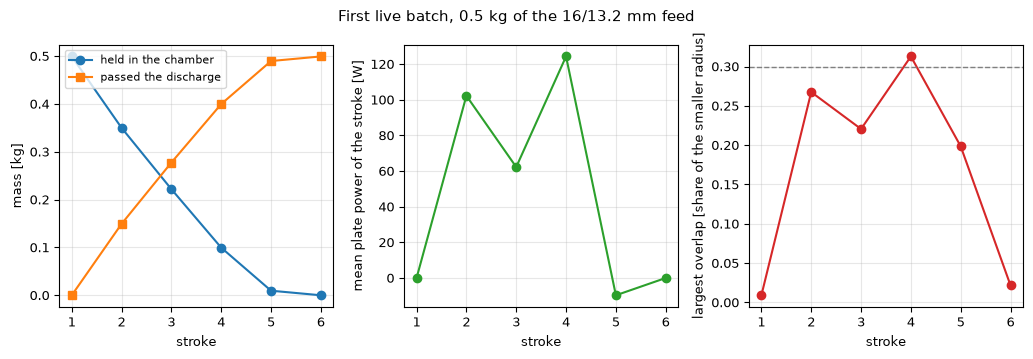

In [10]:
# Figure 3: what the strokes did, from the per-stroke series of the run
rows = attempt["series"]
stroke = [r["stroke"] for r in rows]
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.6))
axes[0].plot(stroke, [r["hold_up_kg"] for r in rows], "o-", label="held in the chamber")
axes[0].plot(stroke, [r["passed_kg"] for r in rows], "s-", label="passed the discharge")
axes[0].set_ylabel("mass [kg]")
axes[0].legend(fontsize=8)
axes[1].plot(stroke, [r["swing_plate_w"] for r in rows], "o-", color="tab:green")
axes[1].set_ylabel("mean plate power of the stroke [W]")
axes[2].plot(stroke, [r["max_overlap"] for r in rows], "o-", color="tab:red")
axes[2].axhline(0.3, color="gray", ls="--", lw=1)
axes[2].set_ylabel("largest overlap [share of the smaller radius]")
for ax in axes:
    ax.set_xlabel("stroke")
fig.suptitle("First live batch, 0.5 kg of the 16/13.2 mm feed")
fig.tight_layout()
plt.show()

Reading the table and figure 3. In stroke 1 the 113 spheres fed (0.499 kg) fall into the chamber and nothing passes: the plate has not yet closed on them and the plate power is zero. In stroke 2 the plate works, at 102.2 W on average, 0.149 kg leaves and the largest overlap jumps from 0.009 to 0.267 of the smaller radius, which is what a loaded bed does and an empty chamber does not; strokes 3 and 4 pass 0.277 and 0.400 kg in total, with the overlap at 0.221 and then 0.313, above the 0.3 of the contact model. By stroke 5 only 6 spheres (0.010 kg) are held and the plate power is slightly negative, -9.7 W, because no bed is loaded any more and the mean over the stroke is slightly negative; in stroke 6 nothing is held and the batch is complete. The figure shows an empty jaw at the ends and a loaded one between them; it does not show a steady state, because a batch of 0.5 kg has passed 80 percent of its mass after four strokes and is complete after six, and a mean power over such a run is not the 25 s mean of a 6 kg test.

The last cell of the method reads what the batch left: the counts of breakage events and progeny, the mass balance, and the product against the measured curve of the same feed.

In [11]:
# What the batch left: breakage counts, mass balance, and the product against the measured curve of the same feed
brk, prod = attempt["breakage"], attempt["product"]
print(f"events {brk['n_events']}, progeny {brk['n_progeny']},",
      f"peak spheres {brk['peak_particles']},",
      f"fines below 4 mm {brk['fines_kg'] * 1000:.1f} g")
print(f"mass balance residual {attempt['mass_balance_residual_kg']:.1e} kg,",
      f"mass passed {prod['total_kg']:.3f} kg")
p80_sim = comparison.d_percent(prod, 0.8)
p50_sim = comparison.d_percent(prod, 0.5)
curve = measured["16/13.2"].product
p80_meas = float(np.interp(80.0, curve["passing_pct"], curve["sizes_mm"]))
print(f"particle simulation: P50 {p50_sim:.1f} mm, P80 {p80_sim:.1f} mm;",
      f"measurement: P80 {p80_meas:.1f} mm")
print(f"largest sphere that left {1e3 * max(prod['sizes_m']):.1f} mm",
      f"against an open side of {case.OPEN_SIDE_MM:.1f} mm")

events 46, progeny 157, peak spheres 115, fines below 4 mm 8.2 g
mass balance residual 3.0e-16 kg, mass passed 0.499 kg
particle simulation: P50 14.2 mm, P80 15.2 mm; measurement: P80 7.8 mm
largest sphere that left 15.9 mm against an open side of 17.5 mm


The cost of the method at full size is in the committed document of the product's bake, `data/derived/dem/jaw-lab.json`, which runs these three feeds with a batch of 6 kg. The cell prints, for each feed, how the run ended, its strokes and steps, the largest number of spheres alive and their product, an upper bound on the particle-steps of the run.

In [12]:
# What the same batches cost at full size, from the committed document of the bake
doc = json.loads((ROOT / "data/derived/dem/jaw-lab.json").read_text(encoding="utf-8"))
print("feed [mm]  status  strokes  steps  peak spheres  steps x peak spheres")
for pt in doc["points"]:
    s = pt["simulation"]
    peak = s["breakage"]["peak_particles"]
    print(f"{pt['feed_class']:>10s} {s['status']:>14s} {s['strokes']:7d} {s['steps']:10d}",
          f"{peak:12d} {s['steps'] * peak:18.3e}")
print("batch fed:", [round(pt["simulation"]["mass_fed_kg"], 3) for pt in doc["points"]], "kg")

feed [mm]  status  strokes  steps  peak spheres  steps x peak spheres
     63/52       complete      83    3886973          295          1.147e+09
 31.5/26.5  overlap_error       5     234850          327          7.680e+07
   16/13.2       complete      54    2528874         1341          3.391e+09
batch fed: [6.001, 5.992, 5.999] kg


The coarse feed needs 83 strokes and 3 886 973 steps, with at most 295 spheres alive, an upper bound of 1.147e+09 particle-steps; the fine feed needs 54 strokes and 2 528 874 steps, but with up to 1341 spheres, which makes 3.391e+09. The middle feed stopped after 5 strokes and 234 850 steps, with 327 spheres alive at its peak, and is the first sign that a full-size run can fail to finish; notebook 02 reads why. The cost therefore does not follow the feed's size in a simple way: the coarse feed needs more strokes, the fine one many more spheres, and the package's README puts a stroke of the coarse feed at 10 to 40 s of wall time, so these runs are far past what a notebook can wait for. The 6 kg of each batch is fed to within a few grams: 6.001, 5.992 and 5.999 kg.

## Results

**Answer:** Following every particle adds the mechanics of the chamber that a population balance folds into two fitted curves: the 46 breakage events of this 0.5 kg batch each have a place, a time and an energy, and the plate power, 124.3 W at its highest stroke here, comes from the force of the plate on the bed instead of from a work index. What the laboratory tests measured is, for each of three narrow feeds at 6.0 Hz and 7.5 mm, a throughput of 798.7, 937.2 and 1220.4 kg/h, a net power of 0.34, 0.1656 and 0.1346 kW, and a product with P80 of 7.12, 7.62 and 7.83 mm.

Two things in the batch above have to be said plainly. First, the mass balance closes, to a residual of 3.0e-16 kg, and the 46 events and 157 progeny leave 8.2 g of fines under the 4 mm minimum sphere, so the replacement rule conserves mass. Second, the product of the live batch is coarser than the measured one: P80 15.2 mm against 7.8 mm for the same feed, with spheres up to 15.9 mm leaving through a gap whose open side is 17.5 mm, where the measured product has nothing above 13.2 mm. The batch also passed the 0.3 reference of the contact model (0.313 in stroke 4) and ran only because its limit was 0.5. A batch of 0.5 kg, a few strokes and no steady state is not a test of the paper's machine and this single comparison proves nothing alone; it is the first sign of a difference that notebooks 02 and 03 follow with the full-size runs and with the two other feeds.

What that costs is also readable in the run: 280 986 steps for six strokes, 46 831 per stroke, over at most 115 spheres, and 3 886 973 steps and up to 1.147e+09 particle-steps for the full batch of 6 kg of the coarse feed, which is why the full batch is read from the committed document rather than run in a notebook.

## Summary

- A population balance replaces the chamber by two fitted curves; a discrete element simulation follows each sphere under Newton's second law with the Hertz contact and breaks it when its event energy passes its fracture energy, drawn from a lognormal law.
- The laboratory jaw of Barrios et al. (2020) was measured at one setting, 7.5 mm at 6.0 Hz, on three narrow feeds: throughput 2.66 to 4.07 times the nominal 300 kg/h, net power falling from 0.34 to 0.1346 kW as the feed gets finer, and every product below 16 mm with P80 near 7 to 8 mm.
- The package runs that jaw: a live batch of 0.5 kg closed its mass balance to 3.0e-16 kg and produced a product coarser than the measured one, which a batch this small cannot settle.
- The cost is the step count, 46 831 steps per stroke at the 3.559 microsecond step and 3 886 973 steps for the full batch of the coarse feed, which puts it out of reach of a notebook.
- Notebook 02 takes the breakage step by step and shows where the method stops working on this jaw; notebook 03 holds the particle simulation against the measurement and against the population balance with a jaw capacity model.

## References

- Barrios, G. K., Jiménez-Herrera, N., Fuentes-Torres, S. N., Tavares, L. M. (2020). DEM simulation of laboratory-scale jaw crushing of a gold-bearing ore using a particle replacement model. Minerals 10(8), 717. https://doi.org/10.3390/min10080717
- Cleary, P. W., Sinnott, M. D. (2015). Simulation of particle flows and breakage in crushers using DEM: Part 1, Compression crushers. Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Cundall, P. A., Strack, O. D. L. (1979). A discrete numerical model for granular assemblies. Geotechnique 29(1), 47-65. https://doi.org/10.1680/geot.1979.29.1.47
- Quist, J. (2012). Cone crusher modelling and simulation. Chalmers University of Technology. http://publications.lib.chalmers.se/records/fulltext/164816/164816.pdf
- Quist, J., Evertsson, C. M. (2016). Cone crusher modelling and simulation using DEM. Minerals Engineering 85, 92-105. https://doi.org/10.1016/j.mineng.2015.11.004
- Santibanez-Leal, F. (2026). crushdem 0.6.0, a soft-sphere discrete element method with particle breakage for crushers, package page and README. https://pypi.org/project/crushdem/
- Tavares, L. M. (2022). Review and further validation of a practical single-particle breakage model. KONA Powder and Particle Journal 39, 62-83. https://doi.org/10.14356/kona.2022012
- Tsuji, Y., Tanaka, T., Ishida, T. (1992). Lagrangian numerical simulation of plug flow of cohesionless particles in a horizontal pipe. Powder Technology 71(3), 239-250. https://doi.org/10.1016/0032-5910(92)88030-L
- Whiten, W. J. (1972). The simulation of crushing plants with models developed using multiple spline regression. Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf